# Занятие 06. Как объясняют любой вход — демо и конспект

Ноутбук идёт в том же порядке, что слайды. У каждого метода:

- **Зачем** — чего не умел предыдущий метод и какую идею добавляет этот;
- **Формула по символам** — что значит каждый символ;
- **Микро-пример** — те же формулы на числах, которые можно проверить руками;
- **Код на настоящих данных** — с псевдокодом перед ним;
- **В чём измеряется** и **на что обращать внимание** — нюансы и границы метода с примерами.

---
# Часть 1. Поделим мир объяснений на два

| | Через вход — занятие 06 | Изнутри модели — занятие 07 |
|---|---|---|
| модель | чёрный ящик | открыта |
| что делаем | меняем вход (закрыть, удалить, заменить) или берём градиент по входу | читаем то, что модель хранит внутри |
| методы | окклюзия, RISE, LIME, leave-one-out, градиент, SmoothGrad, IG | Grad-CAM, внимание и rollout, GNNExplainer, выбор цели у CLIP |
| что нужно | только ответ модели; для градиента — ещё её производная | доступ к устройству: слои, веса, активации |

**Объяснение входа = выбор четырёх компонент.** Каждый метод задаёт (или меняет) одну из них:

| Компонента | Вопрос | Примеры |
|---|---|---|
| **Единица** | что считаем признаком? | пиксель, суперпиксель, токен, слово, окно ряда, ребро, фильм в истории |
| **Процесс** | что делаем с единицей? | градиент; вмешательство — заменить, удалить, замаскировать |
| **Baseline** | на что заменяем? | ноль, среднее, размытие, [MASK], тишина |
| **Цель** | какое число объясняем? | логит, вероятность, разность логитов, скор, косинус |

Цель частично сопряжена со структурой данных, на которой строится объяснение. Методы занятий 04–05 раскладываются так же:

| | PI (04) | SHAP (05) | IG (05) |
|---|---|---|---|
| Единица | признак | признак | признак |
| Процесс | перестановка | замена из фона | градиент по пути |
| Baseline | маргинальное | фон | $x'$ |
| Цель | $R^2$ | логит | логит |

Данные здесь — лишь форма, в которой мы задаём вопрос. Модели — ResNet-34 (ImageNet) на картинке из `skimage`, RoBERTa для тональности твитов и игрушечные функции, которые считаются руками.

## Библиотеки

| Библиотека | Зачем здесь |
|---|---|
| `torchvision` | ResNet-34 с весами ImageNet |
| `captum` | окклюзия, градиент, SmoothGrad, Integrated Gradients по эмбеддингам, удаление признаков |
| `scikit-image` | тестовая картинка и суперпиксели SLIC |
| `lime` | LIME на суперпикселях |
| `transformers` | RoBERTa для тональности |
| `numpy` | микро-примеры: игрушечные модели, которые считаются руками |

In [1]:
import warnings, os; warnings.filterwarnings("ignore"); os.environ["TQDM_DISABLE"] = "1"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F, torchvision
from PIL import Image
from skimage import data
from skimage.segmentation import slic, mark_boundaries
from scipy.stats import spearmanr
from torchvision.transforms import GaussianBlur
from captum.attr import Occlusion, Saliency, NoiseTunnel, LayerIntegratedGradients, FeatureAblation
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)

W = torchvision.models.ResNet34_Weights.IMAGENET1K_V1
net = torchvision.models.resnet34(weights=W).eval()
for p in net.parameters(): p.requires_grad_(False)
pnet = torch.nn.Sequential(net, torch.nn.Softmax(-1)).eval()      # выход — вероятности
CATS = W.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]; STD = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
def show(t): return (t * STD + MEAN).permute(1, 2, 0).clamp(0, 1).numpy()
def prob(x):
    with torch.no_grad(): return pnet(x)

X = W.transforms()(Image.fromarray(data.chelsea()))[None]          # кошка из skimage, 224×224
C = int(prob(X)[0].argmax()); IMG = show(X[0])
BLACK = ((torch.zeros(3, 224, 224) - MEAN) / STD)[None]             # чёрный в пиксельном пространстве
BLUR = GaussianBlur(51, sigma=20)(X)
print("топ-3:", [(CATS[int(i)], round(float(v), 3)) for v, i in zip(*prob(X)[0].topk(3))])

топ-3: [('tiger cat', 0.643), ('tabby', 0.18), ('Egyptian cat', 0.167)]


---
# Часть 2. Что на входах считать признаком

## 2.1. С одной стороны, единица определена модальностью

### Блок «Теория»

Сырой вход модели редко годится как единица объяснения. У картинки 224×224 — 50 176 пикселей; модель устойчива к одной точке, а прогон на каждый пиксель — дорого. **Суперпиксели** — связные куски похожего цвета (алгоритм SLIC, Achanta et al., 2012): несколько десятков единиц, которые человек может прочитать. Так же у текста: модель видит суб-токены (`unwatchable` → `unw` + `atch` + `able`), а объясняют словами. У аддитивных методов (IG, SHAP) вклад слова — сумма вкладов его суб-токенов; у вмешательства это не так: маска одного куска ломает слово, и это уже другой вопрос. У ряда единица — окно, у аудио — клетка спектрограммы время × частота, у графа — ребро, у рекомендаций — фильм в истории.

**Пример.** Чтобы понять, какие части фотографии важны для «кошки», бессмысленно закрывать по одной точке: картинка не изменится. Закрывают куски — глаз, лоб, нос.

### Как устроен код
```
сегменты ← SLIC(картинка, около 50 сегментов)
p0 ← вероятность класса
для каждого сегмента: заменить его размытой версией, падение p
сравнить: убрать 1 пиксель / 1 важнейший сегмент / 5 важнейших
```

суперпикселей: 35
падение p: 1 пиксель -0.0064;  важнейший суперпиксель +0.154;  5 важнейших +0.434


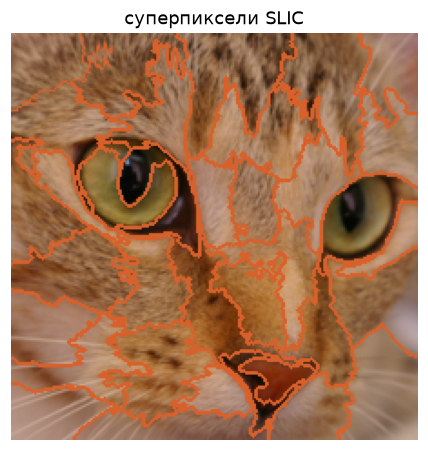

In [2]:
SEG = slic((IMG * 255).astype(np.uint8), n_segments=50, compactness=10, start_label=0)
seg_t = torch.tensor(SEG); P0 = float(prob(X)[0, C])
def drop_after(mask):                                                  # mask: [224, 224] из 0 и 1
    m = mask[None, None].float(); return P0 - float(prob(X * (1 - m) + BLUR * m)[0, C])
drops = np.array([drop_after(seg_t == k) for k in range(SEG.max() + 1)])
one_px = torch.zeros(224, 224); one_px[112, 112] = 1
top5 = torch.tensor(np.isin(SEG, np.argsort(-drops)[:5]))
print(f"суперпикселей: {SEG.max() + 1}")
print(f"падение p: 1 пиксель {drop_after(one_px):+.4f};  важнейший суперпиксель {drops.max():+.3f};  5 важнейших {drop_after(top5):+.3f}")
plt.imshow(mark_boundaries(IMG, SEG, color=(0.85, 0.38, 0.17))); plt.axis("off"); plt.title("суперпиксели SLIC"); plt.show()

**В чём измеряется.** Падение вероятности класса tiger cat, от 0 до 1.

### На что обращать внимание

- **Слишком мелкая единица ничего не показывает.** Модель устойчива к одной точке. Здесь один пиксель меняет вероятность на тысячные, важнейший суперпиксель — на 0,15, пять важнейших — на 0,43.
- **Число единиц — это цена.** Вмешательство требует прогона на каждую единицу или их набор: 50 176 пикселей против 35 суперпикселей.
- **Граница единицы — тоже решение.** Суперпиксель может разрезать объект; другие параметры SLIC дадут другое объяснение.

## 2.2. С другой стороны, единица определена вычислительной сложностью

Обозначим $d$ — число единиц. Сколько прогонов модели нужно каждому методу:

$$\text{окклюзия, LOO: } d \quad\cdot\quad \text{RISE: } N \quad\cdot\quad \text{LIME: } n \quad\cdot\quad \text{Шепли точно: } 2^{d} \quad\cdot\quad \text{градиент: } 1 \quad\cdot\quad \text{IG: } m$$

| Метод | Прогонов | Картинка | Текст | Ряд |
|---|---|---|---|---|
| окклюзия, leave-one-out | $d$ — по единице | 169 окон (35 суперпикселей) | 17 токенов | 12 окон |
| RISE | $N$ масок — гиперпараметр | 1000 | ~1000 по токенам | ~1000 по окнам |
| LIME | $n$ сэмплов — гиперпараметр | 800 | 5000 (по умолчанию в `lime`) | ~1000 по окнам |
| Шепли точно (занятие 05) | $2^d$ | $2^{35} \approx 3{,}4\cdot10^{10}$ | $2^{17} \approx 131\,000$ | $2^{12} = 4096$ |
| градиент | 1 вперёд + 1 назад | 1 | 1 (по эмбеддингам) | 1 |
| Integrated Gradients | $m$ шагов | 128 | 600 | 50 (по умолчанию в `captum`) |

В колонке «Картинка» и у IG на тексте — то, что использовано в этом ноутбуке; остальное — значения по умолчанию или порядок величины. **50 176 пикселей против 35 суперпикселей: укрупнение делает вмешательство возможным.**

---
# Часть 3. Какие есть процессы: вмешательство

## 3.1. Вмешательство или градиент

**Процесс** — что мы делаем с единицей.

| | Вмешательство — в данные | Градиент — через модель |
|---|---|---|
| что делаем | изменить вход и смотреть на выход: заменить, удалить, замаскировать | производная выхода по входу |
| что нужно | модель не трогаем: нужен только её ответ | доступ к вычислению модели (backprop) |
| изменение | конечное | бесконечно малое |
| цена | прогон на каждый вопрос | один обратный проход — все признаки |
| было | 04: перестановка; 05: функция ценности SHAP | 05: saliency, IG |

Оба объясняют один вход $x$. Разница — где меняем (данные или вычисление) и насколько (конечно или бесконечно мало).

**Зачем важно вмешательство:**

1. **Меняем данные, не модель:** нужен только ответ модели — чёрный ящик, API, нет доступа к весам.
2. **Единица — не координата:** суперпиксель, слово, фильм, ребро — по «наличию» производную не взять.
3. **Модель недифференцируема:** деревья, бустинг, ALS, пайплайны с порогами.
4. **Градиент — про бесконечно малое изменение:** у $f = \tanh(2x)$ в точке $x = 2$ наклон 0,0027, а $f(2) - f(0) = 1{,}00$; вопрос «что будет без признака» — про конечное изменение (необходимость, занятие 08).

Общая рамка для таких методов — объяснение через удаление признаков (Covert, Lundberg, Lee, 2021).

## 3.2. Идея 1: окклюзия

### Формула по символам
$$a(R) = f(x) - f\big(x^{R\to b}\big), \qquad a(p) = \frac{1}{|\{R \ni p\}|}\sum_{R \ni p} a(R)$$

| Символ | Что это | В микро-примере |
|---|---|---|
| $x$ | вход — картинка | 4×4 яркости |
| $R$ | окно — набор пикселей | 2×2, шаг 2 → 4 окна |
| $b$ | baseline — чем закрываем окно | 0 (чёрный) или 0,5 (серый) |
| $x^{R\to b}$ | вход, где пиксели окна заменены на $b$ | одна четверть картинки $= b$ |
| $f$ | цель — объясняемое число | $f(x) = \sum w\cdot x = 4{,}8$ |
| $a(R)$ | падение цели при закрытии окна | 4 числа — 4 прогона |
| $a(p)$ | вклад пикселя: среднее по окнам, которые его накрыли | окна не перекрываются: $a(p) = a(R)$ |

### Микро-пример
Картинка 4×4, линейная модель $f = \sum w\cdot x$: веса 1 в правом верхнем углу (яркость 0,9), 0,5 в левом нижнем (яркость 0,6), 0 в остальных.

| Шаг | Что делаем | $f$ | $a(R)$ |
|---|---|---|---|
| 1 | исходная картинка: $1\cdot0{,}9\cdot4 + 0{,}5\cdot0{,}6\cdot4$ | 4,8 | — |
| 2 | закрыть нулём левый верх (модель туда не смотрит) | 4,8 | 0 |
| 3 | закрыть правый верх | 1,2 | 3,6 |
| 4 | закрыть левый низ / правый низ | 3,6 / 4,8 | 1,2 / 0 |
| 5 | baseline 0,5 вместо 0: правый верх / левый низ | 3,2 / 4,6 | 1,6 / 0,2 |

Четыре окна — четыре прогона. С baseline 0,5 отношение вкладов 3 : 1 стало 8 : 1, потому что вклад окна равен $w\cdot(x - b)$: baseline меняет ответ даже у линейной модели.

### На настоящей картинке
Окно 32×32 скользит с шагом 16 (169 прогонов); закрываем baseline-ом и считаем падение вероятности класса. Единица — окно, процесс — замена, baseline — $b$, цель — вероятность класса (Zeiler & Fergus, 2014).

```
pnet ← ResNet-34 + softmax         # цель — вероятность класса
для baseline в (чёрный, размытый, средний цвет):
    карта ← captum.Occlusion(окно 32×32, шаг 16, baseline)
попарные ранговые корреляции карт
```

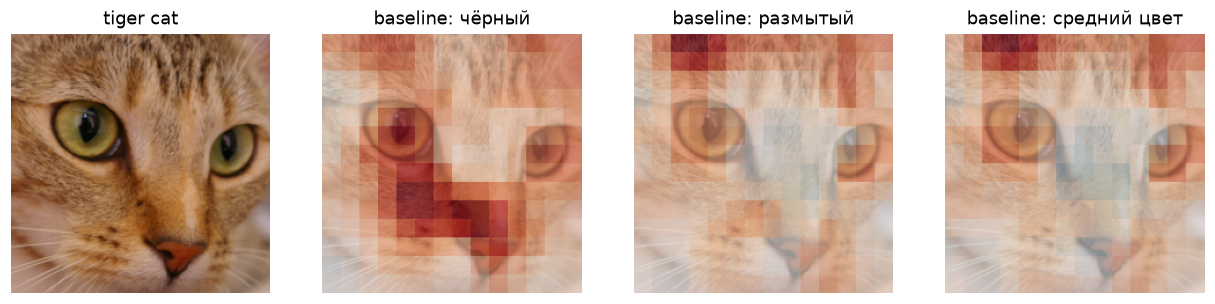

чёрный ~ размытый          0.40
чёрный ~ средний цвет      0.34
размытый ~ средний цвет    0.95
dtype: float64

In [3]:
MEANC = X.mean(dim=(2, 3), keepdim=True).expand_as(X).clone()
occ = Occlusion(pnet)
def occ_map(base, model=pnet):
    a = Occlusion(model).attribute(X, sliding_window_shapes=(3, 32, 32), strides=(3, 16, 16), target=C, baselines=base)
    return a[0].sum(0).numpy() / 3
OCC = {"чёрный": occ_map(BLACK), "размытый": occ_map(BLUR), "средний цвет": occ_map(MEANC)}
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6)); axs[0].imshow(IMG); axs[0].set_title(CATS[C])
for ax, (k, v) in zip(axs[1:], OCC.items()):
    vm = np.abs(v).max(); ax.imshow(IMG); ax.imshow(v, cmap="RdBu_r", vmin=-vm, vmax=vm, alpha=0.6); ax.set_title(f"baseline: {k}")
for ax in axs: ax.axis("off")
plt.show()
ks = list(OCC)
pd.Series({f"{a} ~ {b}": spearmanr(OCC[a].ravel(), OCC[b].ravel())[0] for i, a in enumerate(ks) for b in ks[i + 1:]}).round(2)

**В чём измеряется.** Падение вероятности класса при закрытом окне; красное — закрытие снижает вероятность.

### Нюанс: чем закрыть — baseline задаёт вопрос

- **Baseline задаёт вопрос «по сравнению с чем».** Карты с разными baseline не равны, поэтому baseline всегда пишут рядом с картой. Карты близки только у близких baseline. Здесь размытый и средний цвет — Spearman 0,95, чёрный с размытым — 0,40: чёрное пятно — новый сильный сигнал, которого в данных не было.
- **Цена — число положений окна.** Окно 32 с шагом 16 — 169 прогонов; мельче шаг — больше прогонов.
- **Размер окна — тоже решение:** крупное окно размывает карту, мелкое ничего не меняет (часть 1).

## 3.3. Нюанс: что анализировать — изменение логита или вероятности

### Формула
$$p_c = \frac{e^{z_c}}{\sum_j e^{z_j}}, \qquad \log p_c = z_c - \underbrace{\log\textstyle\sum_j e^{z_j}}_{\mathrm{LSE}(z)}, \qquad \Delta\log p_c = \Delta z_c - \Delta\,\mathrm{LSE}, \qquad \frac{\partial p_c}{\partial z_j} = p_c\,(\delta_{cj} - p_j).$$

$z$ — логиты, $p$ — вероятности после softmax, LSE — логарифм суммы экспонент. Если вмешательство сдвигает логиты **всех** классов на одно число, вероятности не меняются: $\mathrm{softmax}(z + \text{const}) = \mathrm{softmax}(z)$. Вероятность класса $c$ зависит от логитов всех классов.

```
логиты z для tiger cat, tabby, Egyptian cat и LSE: исходно, глаза размыты, лоб размыт
окклюзия с целью «вероятность» и с целью «логит», размытый baseline; ранговая корреляция карт
```

               z tiger cat    LSE  log p     p
исходный             15.55  15.99  -0.44  0.64
глаза размыты        19.35  20.16  -0.81  0.45
лоб размыт           14.18  16.13  -1.95  0.14
исходно:      [('tiger cat', 0.643), ('tabby', 0.18), ('Egyptian cat', 0.167)]
лоб размыт:   [('Egyptian cat', 0.64), ('tabby', 0.202), ('tiger cat', 0.142)]


Spearman(карта по вероятности, карта по логиту) = 0.2


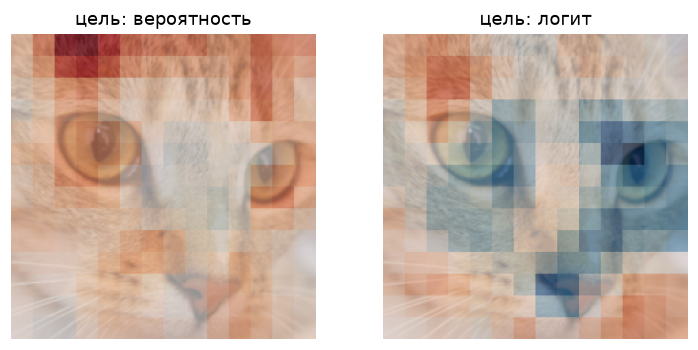

In [4]:
def patch(x, b, y0, y1, x0, x1):
    m = torch.zeros(1, 1, 224, 224); m[..., y0:y1, x0:x1] = 1; return x * (1 - m) + b * m
def top3(x): return [(CATS[int(i)], round(float(v), 3)) for v, i in zip(*prob(x)[0].topk(3))]
def logits_lse(x):
    with torch.no_grad(): z = net(x)[0]
    lse = torch.logsumexp(z, 0); i = C
    return {"z tiger cat": float(z[i]), "LSE": float(lse), "log p": float(z[i] - lse), "p": float((z[i] - lse).exp())}
print(pd.DataFrame({"исходный": logits_lse(X), "глаза размыты": logits_lse(patch(X, BLUR, 70, 130, 20, 210)),
                    "лоб размыт": logits_lse(patch(X, BLUR, 0, 60, 40, 180))}).T.round(2))
print("исходно:     ", top3(X))
print("лоб размыт:  ", top3(patch(X, BLUR, 0, 60, 40, 180)))
occ_logit = occ_map(BLUR, model=net)
print("Spearman(карта по вероятности, карта по логиту) =", round(spearmanr(OCC["размытый"].ravel(), occ_logit.ravel())[0], 2))
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (v, t) in zip(axs, [(OCC["размытый"], "цель: вероятность"), (occ_logit, "цель: логит")]):
    vm = np.abs(v).max(); ax.imshow(IMG); ax.imshow(v, cmap="RdBu_r", vmin=-vm, vmax=vm, alpha=0.6); ax.set_title(t); ax.axis("off")
plt.show()

**В чём измеряется.** Логиты и LSE — в единицах логита; вероятности от 0 до 1; карты — падение вероятности или логита.

### На что обращать внимание

- **Логит и вероятность могут двигаться в разные стороны.** Размытые глаза *повышают* логит tiger cat на 3,80, но LSE растёт сильнее — на 4,17 (у Egyptian cat логит +5,15), и вероятность падает с 0,64 до 0,45. Размытый лоб: логит −1,37, LSE почти не меняется, вероятность 0,14.
- **Похожие классы конкурируют.** Исходно tiger cat 0,64, tabby 0,18, Egyptian cat 0,17; размытый лоб с полосами — и модель говорит Egyptian cat 0,64: полосы отличают tiger cat от других кошек.
- **Карты по логиту и по вероятности разные:** Spearman 0,20. Логит — про класс сам по себе, вероятность — про класс против соседей. Объясняемую величину фиксируют и пишут рядом с картой.

## 3.4. Текст: leave-one-out

### Блок «Теория»

**Leave-one-out**: вклад токена $i$ — $f(x) - f(x_{\setminus i})$. Убрать токен можно двумя способами: заменить на токен-маску или удалить. Маска сохраняет длину и позиции, но такой вход в дообучении на тональности не встречался; удаление даёт обычное, но другое предложение. Цель — разность логитов positive и negative: она не насыщается, как вероятность. В ДЗ-2 вы реализуете оба способа сами; здесь — только маска, через `captum.FeatureAblation`.

### Микро-пример по шагам: «The film is not bad.»

| Вход | Текст | $f$ | Вклад |
|---|---|---|---|
| исходный | The film is not bad. | 3,00 | — |
| маска not | The film is &lt;mask&gt; bad. | −4,26 | not: 7,26 |
| удаление not | The film is bad. | −4,70 | not: 7,70 |
| маска bad | The film is not &lt;mask&gt;. | −1,76 | bad: 4,76 |

Шесть токенов — шесть прогонов на каждый способ убрать токен. Маска и удаление — два baseline, два числа; снова выбираем baseline. Ниже код считает маску; удаление вы реализуете в ДЗ-2.

### Как устроен код
```
RoBERTa-sentiment; f ← logit(positive) − logit(negative)
baseline ← та же строка, все токены кроме <s> и </s> заменены на <mask>
FeatureAblation(f): каждый токен по очереди → <mask>, вклад = f(x) − f(без токена)
```

In [5]:
TXT = "cardiffnlp/twitter-roberta-base-sentiment-latest"
import logging
for name in ["transformers", "transformers.modeling_utils", "transformers.utils.loading_report"]:
    logging.getLogger(name).setLevel(logging.ERROR)                         # скрыть отчёт о загрузке весов
tok = AutoTokenizer.from_pretrained(TXT); rob = AutoModelForSequenceClassification.from_pretrained(TXT).eval()
def f_txt(ids):
    lg = rob(input_ids=ids).logits; return lg[:, 2] - lg[:, 0]
def loo_mask(sentence):
    ids = tok(sentence, return_tensors="pt").input_ids
    bl = torch.full_like(ids, tok.mask_token_id); bl[0, 0], bl[0, -1] = ids[0, 0], ids[0, -1]
    a = FeatureAblation(f_txt).attribute(ids, baselines=bl, feature_mask=torch.arange(ids.shape[1])[None])
    toks = [t.replace("Ġ", "") for t in tok.convert_ids_to_tokens(ids[0])]
    return pd.Series(a[0].detach().numpy()[1:-1], index=toks[1:-1])
SENT = "The plot was overhyped and unwatchable, but the actors were brilliant."
with torch.no_grad(): print("f(x) =", round(float(f_txt(tok(SENT, return_tensors="pt").input_ids)), 2))
print("суб-токены 'unwatchable':", tok.tokenize(" unwatchable"))
loo_mask(SENT).round(2).to_frame("LOO <mask>").T
print("«The film is not bad.»:"); display(loo_mask("The film is not bad.").round(2).to_frame("LOO <mask>").T)

f(x) = 1.54
суб-токены 'unwatchable': ['Ġunw', 'atch', 'able']


«The film is not bad.»:


,The,film,is,not,bad,.
LOO <mask>,0.82,1.3,0.15,7.26,4.76,0.26


**В чём измеряется.** Вклад токена в разность логитов positive − negative.

### На что обращать внимание

- **Маска и удаление — разные baseline.** Маска сохраняет позиции, но это вход не из задачи; удаление меняет длину. В ДЗ-2 вы сравните их числом.
- **Слово из нескольких суб-токенов** (`unwatchable` → `unw` + `atch` + `able`): у аддитивных методов вклад слова — сумма вкладов суб-токенов; при маскировании же один кусок ломает слово.
- **Вклад зависит от контекста** — подробно в части 4.

## 3.5. RISE: чего не видит окклюзия

**Проблема окклюзии — «ИЛИ».** Если у кошки два глаза A и B и модели хватает любого, $f = \max(A, B)$; C — фон, модель его не использует. Убрать A — второй глаз на месте, $f = 1$, вклад 0; так же B и C. Окклюзия говорит «ничего не важно», хотя без обоих глаз $f = 0$. И форма окна задана заранее.

**Идея RISE** (Petsiuk, Das, Saenko, 2018): убирать много кусков сразу, случайно, и смотреть на средний ответ, когда кусок открыт. Глаз A окажется важен там, где B случайно закрыт. Окклюзия — «без чего»; RISE — «с чем, в случайном контексте».

In [6]:
import itertools
f_or = lambda z: max(z[0], z[1])                                  # «ИЛИ»: хватает любого глаза; z = (A, B, C)
full = (1, 1, 1)
print("окклюзия на «ИЛИ»:", [f_or(full) - f_or(tuple(0 if k == j else 1 for k in range(3))) for j in range(3)])

окклюзия на «ИЛИ»: [0, 0, 0]


### RISE: формула по символам

**RISE** (Petsiuk, Das, Saenko, 2018) закрывает не одно окно, а случайную половину картинки. Маска — сетка $7\times7$ из нулей и единиц с вероятностью $p$, растянутая до картинки со случайным сдвигом. Важность пикселя $\lambda$ — средний скор по маскам, где он открыт:
$$S(\lambda) = \mathbb E_M\big[f(x \odot M) \mid M(\lambda) = 1\big] \approx \frac{1}{N p}\sum_{i=1}^N f(x \odot M_i)\, M_i(\lambda).$$

| Символ | Что это | В микро-примере |
|---|---|---|
| $M$ | случайная маска 0/1: открыт кусок или закрыт | набор из трёх 0/1 для A, B, C |
| $p$ | вероятность, что кусок открыт | 0,5 |
| $N$ | число масок = число прогонов | 8 — все $2^3$ наборы |
| $x \odot M$ | вход, где закрыто всё, где маска 0 | картинка без части суперпикселей |
| $M_i(\lambda)$ | открыт ли $\lambda$ в маске $i$ | 1 или 0 |
| $S(\lambda)$ | средний скор, когда $\lambda$ открыт | среднее $f$ по 4 маскам из 8 |

Деление на $Np$ — это среднее: примерно $Np$ масок оставляют $\lambda$ открытым.

### Микро-пример
Модель «И»: $f = A\cdot B + 0{,}2\,C$ (кошка — если есть и ухо A, и глаз B; фон C чуть помогает). Вместо случайных масок — все восемь, так ожидание считается точно.

```
все 8 масок (A, B, C) ∈ {0, 1}³, f для каждой
S(j) ← Σ f·M[j] / (N·p)
```



In [7]:
f_and = lambda z: z[0] * z[1] + 0.2 * z[2]                       # «И»: ухо и глаз; фон слегка помогает
Z = np.array(list(itertools.product([0, 1], repeat=3))); FZ = np.array([f_and(z) for z in Z])
display(pd.DataFrame(Z.T, index=["A", "B", "C"], columns=range(1, 9)).T.assign(f=FZ).T)
S = (FZ[:, None] * Z).sum(0) / (len(Z) * 0.5)
occ3 = [f_and((1, 1, 1)) - f_and(tuple(0 if k == j else 1 for k in range(3))) for j in range(3)]
print("RISE  S(A), S(B), S(C):", S.round(3), "   окклюзия:", np.round(occ3, 2))

,1,2,3,4,5,6,7,8
A,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
B,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0
C,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
f,0.0,0.2,0.0,0.2,0.0,0.2,1.0,1.2


RISE  S(A), S(B), S(C): [0.6  0.6  0.45]    окклюзия: [1.  1.  0.2]


**В микро-примере:** $S(A) = (0 + 0{,}2 + 1{,}0 + 1{,}2)/4 = 0{,}6$, $S(B) = 0{,}6$, $S(C) = 0{,}45$ — фон почти наравне с ухом; окклюзия: 1,0 / 1,0 / 0,2. RISE видит ухо только вместе со случайным глазом — «И» делится.

### RISE на настоящей картинке
```
повторить 1000 раз: случайная сетка 7×7 (p = 0,5) → апсемплинг со сдвигом → маска M
скор ← p(класс | x·M + размытие·(1 − M))
S ← Σ скор·M / (N·p)
```

Spearman(RISE, окклюзия) = 0.01


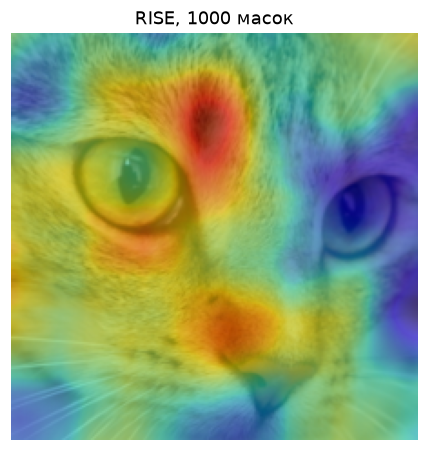

In [8]:
def rise(n=1000, s=7, p=0.5, bs=50, seed=0):
    g = torch.Generator().manual_seed(seed); cell = int(np.ceil(224 / s)); up = (s + 1) * cell
    sal = torch.zeros(224, 224)
    for b in range(0, n, bs):
        grid = (torch.rand(bs, 1, s, s, generator=g) < p).float()
        big = F.interpolate(grid, size=(up, up), mode="bilinear", align_corners=False)
        sh = torch.randint(0, cell, (bs, 2), generator=g)
        M = torch.stack([big[i, :, sh[i, 0]:sh[i, 0] + 224, sh[i, 1]:sh[i, 1] + 224] for i in range(bs)])
        sal += (prob(X * M + BLUR * (1 - M))[:, C][:, None, None] * M[:, 0]).sum(0)
    return (sal / (n * p)).numpy()
RISE = rise()
print("Spearman(RISE, окклюзия) =", round(spearmanr(RISE.ravel(), OCC["размытый"].ravel())[0], 2))
plt.imshow(IMG); plt.imshow(RISE, cmap="jet", alpha=0.5); plt.axis("off"); plt.title("RISE, 1000 масок"); plt.show()

**В чём измеряется.** Средняя вероятность класса при открытом пикселе, от 0 до 1.

### На что обращать внимание

- **RISE и окклюзия задают разные вопросы.** Окклюзия ближе к необходимости («без этого куска»), RISE — к достаточности («вместе со случайной половиной»). Здесь Spearman двух карт 0,01.
- **Цена — число масок.** Здесь 1000 прогонов; меньше масок — шумнее карта.
- **Параметры маски** — размер сетки и $p$ — задают масштаб единицы.

## 3.6. LIME: чего не даёт RISE

**Проблема RISE — важность не нуль у ненужного куска.** На «ИЛИ» RISE даёт A 1, B 1, фону 0,75 — это просто средний ответ модели. Читать можно только относительно среднего: 0,25 / 0,25 / 0. Нет знака и нет меры, насколько оценке верить.

**Идея LIME** (Ribeiro, Singh, Guestrin, 2016): подогнать на тех же случайных масках простую линейную модель и сказать, насколько она точна — веса со знаком и $R^2$.

In [9]:
def lime_exact(fz):                                               # все 8 масок, все веса π = 1: обычный МНК
    F_ = np.array([fz(z) for z in Z]); A_ = np.c_[np.ones(len(Z)), Z]
    coef = np.linalg.lstsq(A_, F_, rcond=None)[0]; r2 = 1 - ((F_ - A_ @ coef) ** 2).sum() / ((F_ - F_.mean()) ** 2).sum()
    return coef.round(3), round(r2, 3)
F_or = np.array([f_or(z) for z in Z])
print("«ИЛИ»: RISE", ((F_or[:, None] * Z).sum(0) / (len(Z) * 0.5)).round(3), " среднее f =", F_or.mean())
print("«ИЛИ»: LIME φ0, φA, φB, φC =", *lime_exact(f_or))

«ИЛИ»: RISE [1.   1.   0.75]  среднее f = 0.75
«ИЛИ»: LIME φ0, φA, φB, φC = [ 0.25  0.5   0.5  -0.  ] 0.667


### LIME: формула по символам
$$g(z') = \varphi_0 + \sum_j \varphi_j z'_j, \qquad \varphi = \arg\min_{\varphi} \sum_{z} \pi(z)\,\big(f(z) - g(z')\big)^2$$

| Символ | Что это | В микро-примере |
|---|---|---|
| $z'$ | 0/1: включён ли суперпиксель | (A, B, C), 8 наборов |
| $f(z)$ | скор модели на картинке по $z'$ | $A\cdot B + 0{,}2\,C$ |
| $g(z')$ | линейный суррогат | $\varphi_0 + \varphi_A A + \varphi_B B + \varphi_C C$ |
| $\pi(z)$ | вес сэмпла — ядро близости | все равны 1 (для простоты) |
| $\varphi_j$ | вес суперпикселя — ответ LIME | считаем МНК |
| $R^2$ | насколько суррогат похож на модель | считаем |

### Микро-пример и три метода рядом

In [10]:
coef, r2 = lime_exact(f_and)
print("«И»: φ0, φA, φB, φC =", coef, " R² =", r2, "  g(1,1,1) =", round(coef.sum(), 2), "вместо", f_and((1, 1, 1)))
pd.DataFrame({"окклюзия": occ3, "RISE": S.round(2), "LIME": coef[1:]}, index=["A (ухо)", "B (глаз)", "C (фон)"]).T

«И»: φ0, φA, φB, φC = [-0.25  0.5   0.5   0.2 ]  R² = 0.684   g(1,1,1) = 0.95 вместо 1.2


,A (ухо),B (глаз),C (фон)
окклюзия,1.0,1.0,0.20
RISE,0.6,0.6,0.45
LIME,0.5,0.5,0.20


**В микро-примере.** $\varphi_0 = -0{,}25$, $\varphi_A = \varphi_B = 0{,}5$, $\varphi_C = 0{,}2$; на полной картинке суррогат даёт 0,95 вместо 1,2, на пустой −0,25 вместо 0; $R^2 = 0{,}68$ — линейная функция не выражает «И», и взаимодействие уха и глаза делится пополам. Одна модель — три ответа: окклюзия — что пропадёт без куска, RISE — скор при случайном контексте, LIME — линейная аппроксимация. Метод называют рядом с картой.

### LIME на настоящей картинке
LIME с занятия 05 на картинке: интерпретируемое представление $z'$ — включён ли каждый суперпиксель; сэмплы — случайные наборы включённых суперпикселей, выключенные заменяются на baseline; линейный суррогат даёт вес каждому суперпикселю.


```
lime_image.LimeImageExplainer(сегментация = SLIC, 800 сэмплов)
показать 5 суперпикселей с наибольшим положительным весом; R² суррогата
```

R² суррогата: 0.63


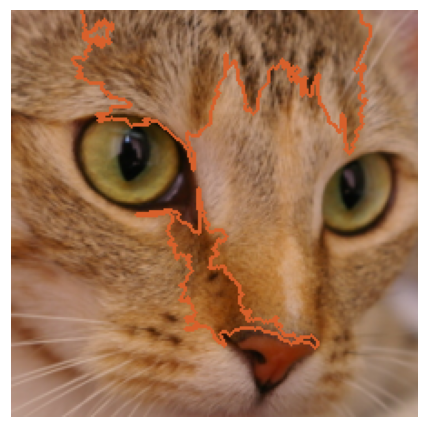

In [11]:
from lime import lime_image
lime_image.tqdm = lambda it, *a, **k: it                              # без прогресс-бара
def clf(batch):
    t = torch.stack([(torch.tensor(b / 255.0, dtype=torch.float32).permute(2, 0, 1) - MEAN) / STD for b in batch])
    return torch.cat([prob(t[k:k + 50]) for k in range(0, len(t), 50)]).numpy()
e = lime_image.LimeImageExplainer(random_state=0).explain_instance(
    (IMG * 255).astype(np.uint8), clf, labels=(C,), top_labels=None, hide_color=None, num_samples=800,
    segmentation_fn=lambda im: slic(im, n_segments=50, compactness=10, start_label=0), random_seed=0)
_, mask = e.get_image_and_mask(C, positive_only=True, num_features=5, hide_rest=False)
print("R² суррогата:", round(e.score, 2))
plt.imshow(mark_boundaries(IMG, mask, color=(0.85, 0.38, 0.17), mode="thick")); plt.axis("off"); plt.show()

**В чём измеряется.** Веса суррогата — изменение вероятности при включении суперпикселя; R² — доля дисперсии прогнозов в окрестности, объяснённая суррогатом.

### На что обращать внимание

- **Нюансы LIME с занятия 05 остаются:** ширина ядра, seed, низкий R². Здесь R² 0,63 на 800 сэмплах.
- **Суперпиксели — тоже решение:** другая сегментация даст другие единицы и другое объяснение.

## 3.7. Ряд, аудио, граф, рекомендации: та же схема

| Форма | Единица | Процесс | Baseline | Цель |
|---|---|---|---|---|
| ряд | окно | замена окна | ноль, среднее ряда, интерполяция, шум | логит класса |
| аудио | клетка время × частота | замена | тишина, шум | логит класса |
| граф | ребро | удаление | нет ребра | вероятность класса узла |
| рекомендации | фильм в истории | удаление и пересчёт вектора пользователя | — | скор, место в топе (Ghazimatin et al., 2020) |

**Уровень ряда** — значение, около которого он колеблется; «среднее ряда» — его оценка. Чем заменить окно — снова вопрос baseline: какая замена честнее, вы проверите числом в ДЗ-2 на синтетике с известной истиной; там же — удаление фильма из истории в рекомендациях.

## 3.8. Рекомендации: модели, которые объясняют себя

Соседские модели по фильмам — item-kNN (Sarwar et al., 2001), SLIM (Ning & Karypis, 2011), EASE (Steck, 2019) — объяснимы по построению, как линейная регрессия на таблицах:
$$s_{ui} = \sum_{j \in H_u} B_{ji}, \qquad \text{вклад фильма } j = B_{ji}, \qquad s_{ui} - s_{ui}\big(H_u \setminus \{j\}\big) = B_{ji}.$$
$H_u$ — история пользователя, $B_{ji}$ — вес «просмотр $j$ говорит о фильме $i$», выученный на всех пользователях. $B$ не зависит от истории, поэтому удаление фильма меняет скор ровно на его вклад, и «потому что вы смотрели X» — точное объяснение. В факторизации (ALS) вектор пользователя пересчитывается по всей истории — это ДЗ-2.

Игрушечные веса для кандидата «Бегущий по лезвию»:

In [12]:
B = pd.Series({"Матрица": 0.30, "Терминатор": 0.25, "Амели": -0.05})       # B_j,«Бегущий по лезвию»
score = B.sum()
pd.DataFrame({"B_j (вклад)": B, "скор без фильма": score - B, "изменение": score - (score - B)}).round(2).assign(**{"скор": round(score, 2)})

,B_j (вклад),скор без фильма,изменение,скор
Матрица,0.30,0.20,0.30,0.5
Терминатор,0.25,0.25,0.25,0.5
Амели,-0.05,0.55,-0.05,0.5


---
# Часть 4. Процесс: градиент

## 4.1. Зачем градиент: цена вмешательства

**Проблема.** Вмешательство требует прогона на каждый вопрос: на кошке окклюзия — 169 прогонов, RISE — 1000, LIME — 800; единица выбрана заранее (суперпиксель, окно).

**Идея.** Чувствительность ко всем входам за один проход: производная выхода по каждому пикселю — backprop. Но нужен доступ к модели, и результат говорит про малый сдвиг. Градиент: дёшево и для каждой единицы, но про бесконечно малое изменение.

## 4.2. Градиент по входу: формула по символам
$$s_j = \left|\frac{\partial f}{\partial x_j}\right|, \qquad \text{у картинки: } s(h, w) = \max_{c \in \{R,G,B\}} \left|\frac{\partial f}{\partial x_{c,h,w}}\right|$$

| Символ | Что это | В примере |
|---|---|---|
| $x_j$ | вход: у картинки — канал $c$ пикселя $(h, w)$ | $x = (x_1, x_2) = (2, 1)$ |
| $f$ | цель — обычно логит класса | $f = \tanh(2x_1) + x_2$ |
| $\partial f/\partial x_j$ | изменение $f$ при малом сдвиге $x_j$ | $\partial f/\partial x_1 = 2(1 - \tanh^2 2x_1)$ |
| $\lvert\cdot\rvert$ | модуль: величина чувствительности без знака | — |
| $\max$ по $c$ | один пиксель — три канала → одно число | у функции каналов нет |
| $s_j$ | карта чувствительности | (0,0027; 1) |

### Микро-пример: $f = \tanh(2x_1) + x_2$ в точке $(2, 1)$

f(2, 1) = 1.9993
градиент:              ∂f/∂x1 = 0.0027,  ∂f/∂x2 = 1
вмешательство (→ 0):   x1: 0.9993,  x2: 1.0000
градиент × вход:       x1: 0.0054,  x2: 1


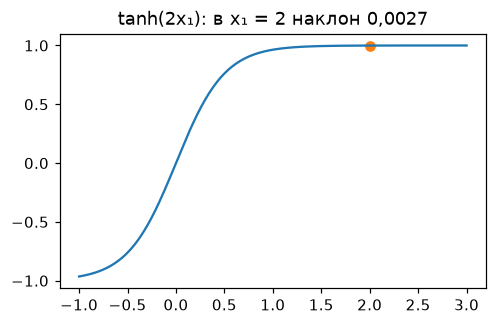

In [13]:
f2 = lambda x1, x2: np.tanh(2 * x1) + x2
d1 = lambda x1: 2 * (1 - np.tanh(2 * x1) ** 2)                    # ∂f/∂x1; ∂f/∂x2 = 1
x0 = (2.0, 1.0)
print(f"f(2, 1) = {f2(*x0):.4f}")
print(f"градиент:              ∂f/∂x1 = {d1(x0[0]):.4f},  ∂f/∂x2 = 1")
print(f"вмешательство (→ 0):   x1: {f2(*x0) - f2(0, x0[1]):.4f},  x2: {f2(*x0) - f2(x0[0], 0):.4f}")
print(f"градиент × вход:       x1: {d1(x0[0]) * x0[0]:.4f},  x2: 1")
t = np.linspace(-1, 3, 300); plt.figure(figsize=(5, 3)); plt.plot(t, np.tanh(2 * t)); plt.scatter([2], [np.tanh(4)], color="C1")
plt.title("tanh(2x₁): в x₁ = 2 наклон 0,0027"); plt.show()

**В микро-примере.** Градиент говорит, что $x_1$ «не важен» (0,0027), хотя без $x_1$ ответ падает так же, как без $x_2$ (1,00 и 1,00). Это насыщение; градиент × вход (0,0054) его не лечит: градиент отвечает на вопрос о малом сдвиге.

## 4.3. SmoothGrad: градиент сети шумный

**Проблема.** Наклон сети скачет от пикселя к пикселю: сеть с ReLU кусочно-линейна, наклон меняется на границах кусков. Карта $|\mathrm{grad}|$ кошки — рябь.

**Идея** (Smilkov et al., 2017): средний наклон в окрестности, а не в точке — добавить шум $\varepsilon \sim \mathcal N(0, \sigma^2)$ $n$ раз и усреднить $|\mathrm{градиент}|$.

### Формула по символам
$$\mathrm{SG}_j(x) = \frac{1}{n}\sum_{k=1}^{n} \left|\frac{\partial f(x + \varepsilon_k)}{\partial x_j}\right|, \qquad \varepsilon_k \sim \mathcal{N}(0, \sigma^2)$$

| Символ | Что это | В примере |
|---|---|---|
| $\varepsilon_k$ | гауссов шум формы входа | одно число на копию |
| $\sigma$ | стандартное отклонение шума — радиус окрестности | 1 (кошка: 0,15 от размаха) |
| $n$ | число копий = число обратных проходов | 10 (кошка: 25) |
| $\lvert\partial f(x + \varepsilon_k)/\partial x_j\rvert$ | модуль наклона в зашумлённой копии | наклон tanh в точке $2 + \varepsilon_k$ |
| $\mathrm{SG}_j$ | средний наклон в окрестности | считаем |

### Микро-пример

In [14]:
rng = np.random.default_rng(0); eps = np.round(rng.normal(0, 1, 10), 2)    # σ = 1, n = 10
display(pd.DataFrame({"x1 + ε": x0[0] + eps, "наклон": d1(x0[0] + eps).round(3)}).T)
big = rng.normal(0, 1, 200_000)
print(f"SmoothGrad: 10 копий — {np.abs(d1(x0[0] + eps)).mean():.3f};  n → ∞ — {np.abs(d1(x0[0] + big)).mean():.3f};  в самой точке — {d1(x0[0]):.4f}")

,0,1,2,3,4,5,6,7,8,9
x1 + ε,2.130,1.870,2.64,2.100,1.460,2.360,3.3,2.95,1.300,0.730
наклон,0.002,0.005,0.00,0.002,0.023,0.001,0.0,0.00,0.044,0.388


SmoothGrad: 10 копий — 0.046;  n → ∞ — 0.137;  в самой точке — 0.0027


**В микро-примере.** Большинство копий лежит в насыщении (наклон — тысячные), копия в точке 0,73 даёт 0,388; среднее по десяти копиям 0,046, в пределе 0,137. $\sigma$ задаёт окрестность, $n$ — точность: на десяти копиях одна копия даёт почти весь ответ.

### Градиент и SmoothGrad на настоящей картинке

Градиент по пикселям — backprop с занятия 05, доведённый до входа: $|\partial f_c / \partial x|$, максимум по каналам. **SmoothGrad** (Smilkov et al., 2017) усредняет градиент по зашумлённым копиям:
$$\mathrm{SG}(x) = \frac1n\sum_{k=1}^n \big|\nabla f(x + \varepsilon_k)\big|, \qquad \varepsilon_k \sim \mathcal N(0, \sigma^2).$$

### Как устроен код
```
|grad| ← captum.Saliency(абсолютное значение), максимум по каналам
SmoothGrad ← captum.NoiseTunnel(Saliency, 25 копий, σ = 0,15 от размаха x)
ранговая корреляция двух карт
```

Spearman(|grad|, SmoothGrad) = 0.19


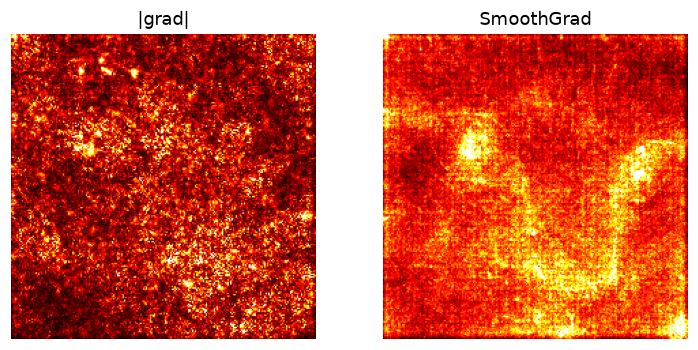

In [15]:
sal = Saliency(net).attribute(X.clone().requires_grad_(True), target=C, abs=True)[0].amax(0).numpy()
sg = NoiseTunnel(Saliency(net)).attribute(X.clone().requires_grad_(True), nt_type="smoothgrad", nt_samples=25,
                                          stdevs=0.15 * float(X.max() - X.min()), target=C, abs=True)[0].amax(0).numpy()
print("Spearman(|grad|, SmoothGrad) =", round(spearmanr(sal.ravel(), sg.ravel())[0], 2))
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (m, t) in zip(axs, [(sal, "|grad|"), (sg, "SmoothGrad")]):
    ax.imshow(m, cmap="hot", vmax=np.quantile(m, 0.99)); ax.set_title(t); ax.axis("off")
plt.show()

**В чём измеряется.** Модуль производной логита по пикселю — изменение логита на единицу нормализованной яркости.

### На что обращать внимание

- **Градиент по входу шумный:** он резко меняется от пикселя к пикселю. Здесь SmoothGrad меняет карту до Spearman 0,19 с исходной.
- **Карта зависит от усреднения** — числа копий и $\sigma$.
- **Насыщение:** в плоской части нелинейности производная около нуля, хотя признак важен (часть 2.1).
- **Голый градиент очень шумен.** На практике — как минимум SmoothGrad.

## 4.4. IG: насыщение не лечится усреднением

**Проблема.** И градиент, и SmoothGrad — про наклон рядом с $x$. В насыщении наклон мал во всей окрестности: на tanh градиент 0,0027, SmoothGrad 0,137, а $f(2) - f(0) = 1{,}00$. Сумма карты ничему не равна.

**Идея** Integrated Gradients (Sundararajan, Taly, Yan, 2017; занятие 05): собрать наклон на всём пути от baseline $x'$ до $x$. Средний наклон вдоль пути × сдвиг признака; сумма вкладов $= f(x) - f(x')$ — полнота.

### Формула по символам
$$\mathrm{IG}_j = (x_j - x'_j)\int_0^1 \frac{\partial f\big(x' + \alpha(x - x')\big)}{\partial x_j}\,d\alpha \;\approx\; (x_j - x'_j)\,\frac{1}{m}\sum_{k=1}^{m} \frac{\partial f\big(x' + \alpha_k(x - x')\big)}{\partial x_j}$$

| Символ | Что это | В микро-примере |
|---|---|---|
| $x'$ | baseline — точка отсчёта | (0, 0) |
| $\alpha$ | положение на пути от $x'$ ($\alpha = 0$) до $x$ ($\alpha = 1$) | $\alpha_k$ = 0,125 · 0,375 · 0,625 · 0,875 |
| $m$ | число шагов | 4, затем 50 |
| $x_j - x'_j$ | насколько признак сдвинулся | $x_1$: 2, $x_2$: 1 |
| полнота | $\sum_j \mathrm{IG}_j = f(x) - f(x')$ | 1,9993 |
| $\delta$ | остаток полноты — проверка шагов | считаем |

### Микро-пример

In [16]:
def ig_tanh(m):
    al = (np.arange(m) + 0.5) / m                                  # середины отрезков пути
    return al, x0[0] * d1(al * x0[0]).mean(), x0[1] * 1.0
al, ig1, ig2 = ig_tanh(4)
display(pd.DataFrame({"α": al, "x1 на пути": al * x0[0], "∂f/∂x1": d1(al * x0[0]).round(3)}))
for m in (4, 50):
    _, a1, a2 = ig_tanh(m)
    print(f"m = {m:2d}: IG1 = {a1:.4f}, IG2 = {a2:.0f};  сумма {a1 + a2:.4f} против f(x) − f(x′) = {f2(*x0) - f2(0, 0):.4f},  остаток {f2(*x0) - f2(0, 0) - a1 - a2:.4f}")

,α,x1 на пути,∂f/∂x1
0,0.125,0.25,1.573
1,0.375,0.75,0.361
2,0.625,1.25,0.053
3,0.875,1.75,0.007


m =  4: IG1 = 0.9974, IG2 = 1;  сумма 1.9974 против f(x) − f(x′) = 1.9993,  остаток 0.0019
m = 50: IG1 = 0.9993, IG2 = 1;  сумма 1.9993 против f(x) − f(x′) = 1.9993,  остаток -0.0000


**В микро-примере.** Градиент в точке давал $x_1$ 0,0027, IG — 0,997: IG собирает наклон там, где функция ещё росла.

### IG на картинке: полнота и baseline

Integrated Gradients с занятия 05 переносятся на картинку без изменений: полнота $\sum_j \mathrm{IG}_j = f(x) - f(x')$ выполняется, а baseline $x'$ — чёрный, размытый, шум — задаёт вопрос «по сравнению с чем». На слайдах — две карты для одной картинки. Сравнить три baseline числом и сформулировать, на какой вопрос отвечает каждый, — задача части 2 ДЗ-2, поэтому кода здесь нет.

На слайдах: чёрный baseline — $\Sigma\,\mathrm{IG} = 16{,}01$ при $f(x) - f(x') = 15{,}97$; размытый — 12,73 при 12,77; остаток около 0,04 на 128 шагах. Полнота есть, но «по сравнению с чем» снова наш вопрос (Kindermans et al., 2017).

## 4.5. IG по эмбеддингам тоже можно: микро-пример

$$\mathrm{IG}_t = \sum_d \mathrm{IG}_{t,d}, \qquad \text{для линейной } f = w^\top \textstyle\sum_t e_t:\quad \mathrm{IG}_{t,d} = (e_{t,d} - e'_{t,d})\, w_d$$

Два токена, эмбеддинг из трёх чисел, $w = (1, 2, -1)$, baseline — эмбеддинг маски $(0;\,0{,}1;\,0)$. У линейной модели наклон постоянен, интеграл = сдвиг × вес.

In [17]:
E = np.array([[0.4, -0.2, 0.7], [0.1, 0.9, -0.3]]); EB = np.array([[0.0, 0.1, 0.0]] * 2); w = np.array([1.0, 2.0, -1.0])
IGt = (E - EB) * w
display(pd.DataFrame(IGt, index=["токен 1", "токен 2"], columns=["d1", "d2", "d3"]).assign(**{"IG токена": IGt.sum(1)}).round(2))
print(f"полнота: {IGt.sum():.1f} = f(x) − f(x′) = {(E.sum(0) * w).sum():.1f} − {(EB.sum(0) * w).sum():.1f}")

,d1,d2,d3,IG токена
токен 1,0.4,-0.6,-0.7,-0.9
токен 2,0.1,1.6,0.3,2.0


полнота: 1.1 = f(x) − f(x′) = 1.5 − 0.4


**В микро-примере.** Координаты одного токена бывают разного знака; вклад токена — их сумма. У настоящей сети путь нелинеен — шаги проверяют по остатку.

### IG по эмбеддингам на примере

Токен — номер в словаре, по нему производную не взять. Поэтому градиент берут по **эмбеддингам** — векторам, в которые превращаются токены, — а вклад токена получают, сложив атрибуции по размерности эмбеддинга. Здесь IG от baseline «все токены — маски» (`LayerIntegratedGradients` по слою эмбеддингов).

### Как устроен код
```
LayerIntegratedGradients(f, слой эмбеддингов RoBERTa)
baseline ← все токены, кроме <s> и </s>, — <mask>; 600 шагов
вклад токена ← сумма по размерности эмбеддинга; проверка полноты; сравнение с LOO
```

In [18]:
ids = tok(SENT, return_tensors="pt").input_ids
bl = ids.clone(); bl[0, 1:-1] = tok.mask_token_id
lig = LayerIntegratedGradients(f_txt, rob.roberta.embeddings)
att, delta = lig.attribute(ids, baselines=bl, n_steps=600, internal_batch_size=60, return_convergence_delta=True)
ig_tok = att.sum(-1)[0, 1:-1].detach().numpy()
lo = loo_mask(SENT)
print(f"остаток полноты: {abs(float(delta)):.3f};  Spearman(IG, LOO) = {spearmanr(ig_tok, lo.values)[0]:.2f}")
pd.DataFrame({"IG": ig_tok, "LOO <mask>": lo.values}, index=lo.index).round(2).T

остаток полноты: 0.052;  Spearman(IG, LOO) = 0.88


,The,plot,was,over,hyp,ed,and,unw,atch,able,",",but,the,actors,were,brilliant,.
IG,-0.61,-1.81,0.45,-0.40,-0.63,-1.13,-0.18,-1.98,-1.39,-1.22,0.18,1.47,0.23,0.45,0.58,6.22,-0.49
LOO <mask>,0.10,-0.31,0.22,-0.01,-0.19,-0.25,-0.42,-1.30,-1.42,-0.47,1.10,3.55,2.15,1.72,2.07,5.11,1.11


**В чём измеряется.** Вклад токена в разность логитов positive − negative.

### На что обращать внимание

- **Число шагов проверяют по полноте.** Путь в пространстве эмбеддингов сильно нелинеен: здесь на 600 шагах остаток около 0,05, на 100 шагах он был больше суммы самих атрибуций.
- **Baseline у текста — тоже решение:** маска, паддинг или нейтральное слово дают разные вопросы.
- **Здесь IG и LOO хорошо согласуются** (Spearman около 0,9) — но это свойство этого предложения и этой модели, а не общее правило.

## 4.6. Но градиент не универсален — его иногда нет

| Форма | Градиент | Если нет — вмешательство |
|---|---|---|
| картинка, ряд, аудио | есть | окклюзия, RISE, замена окна или клетки |
| текст | по эмбеддингам | маска, удаление слова |
| граф | по весам рёбер, если сделать их непрерывными | удаление ребра |
| рекомендации (ALS), деревья | нет | удаление из истории; TreeSHAP (занятие 05) |

Процесс — выбор. Иногда выбора нет: только вмешательство.

---
# Часть 5. Хрупкие места

## 5.1. Замена уводит вход из распределения

### Блок «Теория»

Вмешательство создаёт вход, которого в данных не было, и модель может отвечать на сам артефакт. Тогда падение скора говорит не о важности закрытого куска, а о реакции модели на новый узор. Отсюда метрики, которые это учитывают (ROAR, Hooker et al., 2019) — занятие 08.

### Как устроен код
```
сетка мелких квадратов 16×16 с шагом 40
закрыть их чёрным и размытием; топ-1 класс и вероятность кошки
```

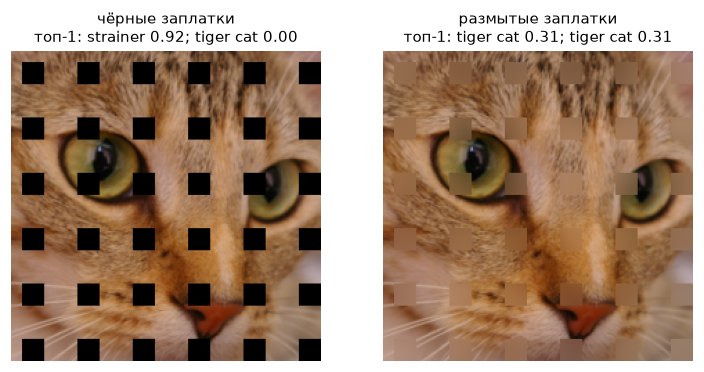

In [19]:
mg = torch.zeros(1, 1, 224, 224)
for yy in range(8, 224, 40):
    for xx in range(8, 224, 40): mg[..., yy:yy + 16, xx:xx + 16] = 1
fig, axs = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, (k, b) in zip(axs, [("чёрные заплатки", BLACK), ("размытые заплатки", BLUR)]):
    xo = X * (1 - mg) + b * mg; pr = prob(xo)[0]
    ax.imshow(show(xo[0])); ax.set_title(f"{k}\nтоп-1: {CATS[int(pr.argmax())]} {float(pr.max()):.2f}; tiger cat {float(pr[C]):.2f}", fontsize=10); ax.axis("off")
plt.show()

**В чём измеряется.** Вероятности классов, от 0 до 1.

### На что обращать внимание

- **Узор заплаток — сам по себе признак.** Здесь чёрные квадраты превращают кошку в дуршлаг (strainer 0,92), а размытые оставляют tiger cat (0,31).
- **Baseline подбирают близким к данным** и сверяют вмешательство с другими процессами.
- **Тот же эффект на таблицах:** перестановка при коррелированных признаках создаёт объекты вне данных (занятие 04).

## 5.2. Одно число на токен не описывает композицию

### Блок «Теория»

Атрибуция через вход даёт одно число на единицу. Текст композиционен: «not» переворачивает следующее слово. Одно число на токен честно отвечает «что изменится без этого токена в этом контексте», но не описывает правило «not инвертирует».

### Как устроен код
```
для четырёх предложений: f(x) и LOO <mask> по токенам
```

In [20]:
rows = {}
for s in ["The film is good.", "The film is not good.", "The film is bad.", "The film is not bad."]:
    with torch.no_grad(): fx = float(f_txt(tok(s, return_tensors="pt").input_ids))
    lo = loo_mask(s); rows[s] = {"f(x)": fx, "not": lo.get("not", np.nan), "good": lo.get("good", np.nan), "bad": lo.get("bad", np.nan)}
pd.DataFrame(rows).T.round(2)

,f(x),not,good,bad
The film is good.,5.38,NaN,4.66,NaN
The film is not good.,-4.75,-8.96,-2.99,NaN
The film is bad.,-4.70,NaN,NaN,-5.42
The film is not bad.,3.00,7.26,NaN,4.76


**В чём измеряется.** Разность логитов positive − negative и вклады токенов в неё.

### На что обращать внимание

- **Одно слово — противоположные знаки.** Здесь вклад `not` −8,96 в «not good» и +7,26 в «not bad».
- **Вклад зависит от соседей:** `bad` в «not bad» получает +4,76, `good` в «not good» — −2,99.
- **Это свойство любых аддитивных объяснений** — LOO, IG, SHAP: взаимодействия слов одной колонкой чисел не выразить.

## 5.3. Единица режет событие; насыщение и шум градиента

- **Граница единицы может разрезать событие.** Если сетку окон ряда сдвинуть, событие окажется в двух окнах, и замена одного окна уберёт только половину. Практика — несколько сеток или перекрывающиеся окна; окклюзия со сдвигом меньше окна так и делает.
- **Насыщение:** производная около нуля, хотя признак важен (части 3.1 и 4.2; на занятии 05 у срока кредита grad × input сменил знак).
- **Шум:** карта градиента зависит от усреднения (часть 4.3). Голый градиент очень шумен — на практике как минимум SmoothGrad.
- **Сдвиг входа:** постоянный сдвиг входа, который модель компенсирует, меняет атрибуции многих методов (Kindermans et al., 2017).

---
# Итог: шесть форм — 4 свободных параметра

| Форма | Единица | Процесс | Baseline | Цель |
|---|---|---|---|---|
| картинка | суперпиксель, окно | окклюзия, RISE, LIME; градиент, IG | размытие, чёрный, средний цвет | вероятность, логит |
| текст | слово (сумма суб-токенов) | маска, удаление; IG по эмбеддингам | [MASK], удаление | разность логитов |
| ряд | окно | замена; градиент | ноль, среднее, интерполяция | логит класса |
| аудио | клетка время × частота | замена; градиент | тишина, шум | логит класса |
| граф | ребро | удаление; градиент по весам рёбер | нет ребра | вероятность класса узла |
| рекомендации | фильм в истории | удаление и пересчёт | — | скор, место в топе |

В каждой клетке — свободный параметр. Их всегда пишите рядом с картой.

**ДЗ-2:** выдача задерживается; примерный план — на слайде (части: таблицы, вход, внутри модели, итоговая таблица; ≈ 5 часов; дедлайн — перед занятием 08–09).

## Литература
- Achanta et al. SLIC superpixels compared to state-of-the-art superpixel methods. TPAMI 2012.
- Zeiler & Fergus. Visualizing and understanding convolutional networks. ECCV 2014.
- Petsiuk, Das, Saenko. RISE: randomized input sampling for explanation of black-box models. BMVC 2018.
- Ribeiro, Singh, Guestrin. «Why should I trust you?». KDD 2016.
- Simonyan, Vedaldi, Zisserman. Deep inside convolutional networks. 2014. Smilkov et al. SmoothGrad: removing noise by adding noise. arXiv:1706.03825, 2017.
- Sundararajan, Taly, Yan. Axiomatic attribution for deep networks. ICML 2017.
- Sturmfels, Lundberg, Lee. Visualizing the impact of feature attribution baselines. Distill 2020. Mamalakis, Barnes, Ebert-Uphoff. Carefully choose the baseline. arXiv:2208.09473.
- Covert, Lundberg, Lee. Explaining by removing: a unified framework for model explanation. JMLR 2021.
- Kindermans et al. The (un)reliability of saliency methods. arXiv:1711.00867.
- Hooker, Erhan, Kindermans, Kim. A benchmark for interpretability methods in deep neural networks. NeurIPS 2019.
- Ghazimatin, Balalau, Saha Roy, Weikum. PRINCE: provider-side interpretability with counterfactual explanations in recommender systems. WSDM 2020.
- Sarwar, Karypis, Konstan, Riedl. Item-based collaborative filtering recommendation algorithms. WWW 2001.
- Ning & Karypis. SLIM: sparse linear methods for top-N recommender systems. ICDM 2011.
- Steck. Embarrassingly shallow autoencoders for sparse data. WWW 2019.